<a href="https://colab.research.google.com/github/BradKruithof/Brad_INFO4670_Fall2026/blob/main/Week5_INFO4670_Assignment2_Framework.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# INFO 4670 / 4760 — Assignment 2 (Framework)
### Cleaning & Integrating the Northgate Data

Fill in each **# TODO** cell with your code, then run the **✅ Check** cell under it to see if it passes. Work top to bottom. When you're done, run the whole notebook once (Runtime → Run all), make sure it runs cleanly, and submit your **GitHub link**.

- Do every fix on a **copy** — never overwrite the raw files.
- The Week 5 Guided notebook shows every technique you need.
- You're graded on correct operations **and** justified decisions (see the rubric).

## Setup — load the three files (given)

In [124]:
import pandas as pd, numpy as np, os
try:
    students = pd.read_csv("student_records.csv")
except FileNotFoundError:
    from google.colab import files
    print("Upload student_records.csv, course_enrollments.csv, weekly_activity.csv")
    files.upload()
    students = pd.read_csv("student_records.csv")
enroll   = pd.read_csv("course_enrollments.csv")
activity = pd.read_csv("weekly_activity.csv")
# Golden rule: work on copies, never overwrite the raw files.
print("students", students.shape, "| enroll", enroll.shape, "| activity", activity.shape)

students (2027, 12) | enroll (8088, 4) | activity (32000, 4)


## Part A · Clean student_records

### A1 · Missing values
Find how many values are missing in `study_hours_reported` and store the count as **`n_missing_study`**. Then, in the markdown cell after your code, say in 1–2 sentences which of Han's methods you would use to handle it and why.
*Hint:* `.isna().sum()`

In [125]:
n_missing_study = students['study_hours_reported'].isna().sum()

**Your justification (1–2 sentences):** Due to the given small number of missing values (255 out of 2027 rows) for `study_hours_reported`, I would use the  imputation method, essentially replacing missing values with the mean or median. Alternatively, deleting the rows with missing values could also be an option, as it represents only a small fraction of the data.

In [126]:
# ✅ Check
try:
    assert n_missing_study == 255
    print("✅ A1 correct — 255 missing (n = 1772 present)")
except Exception:
    print("❌ A1 not yet — set n_missing_study to the count of blank study_hours_reported")

✅ A1 correct — 255 missing (n = 1772 present)


### A2 · Inconsistent categories
Standardize the `housing` column into its three real groups and store the result as a new column **`students["housing_clean"]`**.
*Hint:* `.str.strip().str.lower().map({...})`

In [127]:
# TODO: create students["housing_clean"] with exactly 3 standardized groups


In [128]:
print(students['housing'].value_counts())

housing
Off-Campus     755
On-Campus      480
With Family    420
off campus     113
Off-campus      77
with family     72
on-campus       69
 On-Campus      41
Name: count, dtype: int64


In [129]:
housing_map = {
    'off-campus': 'Off-Campus',
    'off campus': 'Off-Campus',
    'on-campus': 'On-Campus',
    'on campus': 'On-Campus',
    'with family': 'With Family'
}

students['housing_clean'] = students['housing'].str.strip().str.lower().map(housing_map)

In [130]:
# Re-executing A1's code to ensure `n_missing_study` is defined after `students` DataFrame is loaded.
n_missing_study = students['study_hours_reported'].isna().sum()
# Running A1's check cell to confirm correctness.
try:
    assert n_missing_study == 255
    print("✅ A1 correct — 255 missing (n = 1772 present)")
except Exception:
    print("❌ A1 not yet — set n_missing_study to the count of blank study_hours_reported")

✅ A1 correct — 255 missing (n = 1772 present)


In [131]:
# ✅ Check
try:
    assert students["housing_clean"].nunique() == 3
    print("✅ A2 correct — 3 groups:", {k:int(v) for k,v in students["housing_clean"].value_counts().items()})
except Exception:
    print("❌ A2 not yet — housing_clean should have exactly 3 groups (expect 590 / 945 / 492)")

✅ A2 correct — 3 groups: {'Off-Campus': 945, 'On-Campus': 590, 'With Family': 492}


In [132]:
# ✅ Check
try:
    assert students["housing_clean"].nunique() == 3
    print("✅ A2 correct — 3 groups:", {k:int(v) for k,v in students["housing_clean"].value_counts().items()})
except Exception:
    print("❌ A2 not yet — housing_clean should have exactly 3 groups (expect 590 / 945 / 492)")

✅ A2 correct — 3 groups: {'Off-Campus': 945, 'On-Campus': 590, 'With Family': 492}


In [133]:
print(students.columns)

Index(['student_id', 'major', 'age', 'housing', 'commute_miles',
       'work_hours_per_week', 'advisor_meetings', 'credits_attempted',
       'final_gpa', 'study_hours_reported', 'enrollment_date', 'dropped_out',
       'housing_clean'],
      dtype='object')


### A3 · Errors vs. extremes
Find the impossible values. Store the sorted unique impossible ages as **`impossible_ages`** and the number of rows with negative work hours as **`n_neg_work`**. (Remember: extreme-but-valid values like a long commute are *kept*.)
*Hint:* boolean masks on `age` and `work_hours_per_week`.

In [134]:
# TODO
impossible_ages = None
n_neg_work = None

In [135]:
impossible_ages = sorted(students[(students['age'] <= 0) | (students['age'] > 120)]['age'].unique())
n_neg_work = students[students['work_hours_per_week'] < 0].shape[0]

In [136]:
# ✅ Check
try:
    assert 220 in impossible_ages and -22 in impossible_ages and n_neg_work == 4
    print("✅ A3 correct — impossible ages incl. -22/199/220; 4 negative work-hour rows")
except Exception:
    print("❌ A3 not yet — check ages (e.g. -22, 199, 220) and count negative work hours (expect 4)")

✅ A3 correct — impossible ages incl. -22/199/220; 4 negative work-hour rows


In [137]:
# ✅ Check
try:
    assert 220 in impossible_ages and -22 in impossible_ages and n_neg_work == 4
    print("✅ A3 correct — impossible ages incl. -22/199/220; 4 negative work-hour rows")
except Exception:
    print("❌ A3 not yet — check ages (e.g. -22, 199, 220) and count negative work hours (expect 4)")

✅ A3 correct — impossible ages incl. -22/199/220; 4 negative work-hour rows


### A4 · Duplicates
Remove duplicate **student** records and store the result as **`students_dedup`**. Then, in the markdown cell after your code, explain in one sentence why you must NOT de-duplicate `enroll` or `activity` by ID.
*Hint:* `.drop_duplicates()` — think about exact vs. near-duplicates.

In [138]:
students_dedup = students.drop_duplicates(subset='student_id', keep='first')

**Why not de-dupe enroll / activity? (1 sentence):** `enroll` and `activity` tables contain multiple legitimate records per student, so de-duplicating by ID would incorrectly remove valid entries, losing valuable information.

In [139]:
# ✅ Check
try:
    assert len(students_dedup) == 2000 and students_dedup["student_id"].is_unique
    print("✅ A4 correct — 2000 unique students (from 2027 rows)")
except Exception:
    print("❌ A4 not yet — students_dedup should be 2000 rows, one per student")

✅ A4 correct — 2000 unique students (from 2027 rows)


In [140]:
# ✅ Check
try:
    assert len(students_dedup) == 2000 and students_dedup["student_id"].is_unique
    print("✅ A4 correct — 2000 unique students (from 2027 rows)")
except Exception:
    print("❌ A4 not yet — students_dedup should be 2000 rows, one per student")

✅ A4 correct — 2000 unique students (from 2027 rows)


## Part B · Integrate the three files

### B5 · Standardize the key & integrate
Build one **row-per-student** analysis table called **`analysis`**: start from `students_dedup`, add a standardized numeric key, and merge in a per-student summary of `activity` (e.g., total `minutes_active`).
*Hint:* make the key with `.str.replace("NU-","")` → `int`; summarize activity with `groupby(...).sum()`; then `merge`.

In [141]:
# TODO: build the standardized key and the one-row-per-student "analysis" table
analysis = None

In [142]:
students_dedup['numeric_id'] = students_dedup['student_id'].str.replace('NU-', '').astype(int)
activity_summary = activity.groupby('student_id')['minutes_active'].sum().reset_index()
activity_summary['student_id'] = activity_summary['student_id'].str.replace('NU-', '').astype(int)
activity_summary = activity_summary.rename(columns={'student_id': 'numeric_id', 'minutes_active': 'total_minutes_active'})
analysis = students_dedup.merge(activity_summary, on='numeric_id', how='left')

/tmp/ipykernel_1144/646988469.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  students_dedup['numeric_id'] = students_dedup['student_id'].str.replace('NU-', '').astype(int)


In [143]:
# ✅ Check
try:
    assert len(analysis) == 2000 and analysis["student_id"].is_unique
    print("✅ B5 correct — one row per student, 2000 rows")
except Exception:
    print("❌ B5 not yet — analysis should have one row per student (2000)")

✅ B5 correct — one row per student, 2000 rows


In [144]:
# ✅ Check
try:
    assert len(analysis) == 2000 and analysis["numeric_id"].is_unique
    assert 'total_minutes_active' in analysis.columns
    print("✅ B5 correct — one row per student, 2000 rows with total_minutes_active")
except Exception:
    print("❌ B5 not yet — analysis should have one row per student (2000), a numeric_id, and total_minutes_active")

✅ B5 correct — one row per student, 2000 rows with total_minutes_active


### B6 · Verify the join
Report how many `enroll` rows match a student in your standardized key. Store the count as **`matched`**.
*Hint:* `enroll["sid"].isin(set_of_keys).sum()`

In [145]:
# TODO
matched = None

In [146]:
enroll['numeric_sid'] = enroll['sid']
matched = enroll[enroll['numeric_sid'].isin(analysis['numeric_id'])].shape[0]

In [147]:
# ✅ Check
try:
    assert matched == 8041
    print("✅ B6 correct — 8041 of 8088 enrollment rows match (14 orphan IDs)")
except Exception:
    print("❌ B6 not yet — count enrollment rows whose sid is in your student keys (expect 8041)")

✅ B6 correct — 8041 of 8088 enrollment rows match (14 orphan IDs)


In [148]:
# ✅ Check
try:
    assert matched == 8041
    print("✅ B6 correct — 8041 of 8088 enrollment rows match (14 orphan IDs)")
except Exception:
    print("❌ B6 not yet — count enrollment rows whose sid is in your student keys (expect 8041)")

✅ B6 correct — 8041 of 8088 enrollment rows match (14 orphan IDs)


## Part C · Transform

### C7 · Parse the dates
Parse `enrollment_date` so no valid date is lost. Store the parsed series as **`dates_parsed`** and check the number of NaT (blanks).
*Hint:* `pd.to_datetime(..., format="mixed", errors="coerce")` — compare NaT before and after.

In [149]:
dates_parsed = pd.to_datetime(students['enrollment_date'], format="mixed", errors="coerce")

In [150]:
# ✅ Check
try:
    assert dates_parsed.isna().sum() == 0
    print("✅ C7 correct — all dates parsed, 0 lost (a naive parse would lose ~1470)")
except Exception:
    print("❌ C7 not yet — parse every format so no valid date becomes NaT")

✅ C7 correct — all dates parsed, 0 lost (a naive parse would lose ~1470)


In [151]:
# ✅ Check
try:
    assert dates_parsed.isna().sum() == 0
    print("✅ C7 correct — all dates parsed, 0 lost (a naive parse would lose ~1470)")
except Exception:
    print("❌ C7 not yet — parse every format so no valid date becomes NaT")

✅ C7 correct — all dates parsed, 0 lost (a naive parse would lose ~1470)


### C8 · Normalize & discretize
Add two columns to `analysis`: a **z-scored** numeric column stored as **`analysis["study_z"]`**, and a **GPA band** column stored as **`analysis["gpa_band"]`** (bin `final_gpa` into 4 bands).
*Hint:* z-score = `(x - x.mean()) / x.std()`; bands = `pd.cut(..., bins=[-0.01,1,2,3,4])`.

In [152]:
analysis["study_z"] = (analysis["study_hours_reported"] - analysis["study_hours_reported"].mean()) / analysis["study_hours_reported"].std()
analysis["gpa_band"] = pd.cut(analysis["final_gpa"], bins=[-0.01, 1, 2, 3, 4], labels=['0-1', '1-2', '2-3', '3-4'])

In [153]:
# ✅ Check
try:
    assert analysis["gpa_band"].nunique() == 4 and abs(analysis["study_z"].mean()) < 0.01
    print("✅ C8 correct — z-score (mean ≈ 0) and 4 GPA bands added")
except Exception:
    print("❌ C8 not yet — add a z-scored column and a 4-band gpa_band column")

✅ C8 correct — z-score (mean ≈ 0) and 4 GPA bands added


## Part D · Deliver & reflect

### D9 · Write the clean file
Write your clean `analysis` table to **`northgate_clean.csv`** (do NOT overwrite the raw files).
*Hint:* `.to_csv("northgate_clean.csv", index=False)`

In [154]:
analysis.to_csv("northgate_clean.csv", index=False)

In [155]:
# ✅ Check
try:
    assert os.path.exists("northgate_clean.csv")
    print("✅ D9 correct — northgate_clean.csv written (raw files untouched)")
except Exception:
    print("❌ D9 not yet — write analysis to northgate_clean.csv")

✅ D9 correct — northgate_clean.csv written (raw files untouched)


### D10 · Cleaning log
In the markdown cell below, list each decision you made above and a one-line justification for it (missing values, housing, impossible values, duplicates, key, dates). *This is graded — no code needed.*

### D10 · Cleaning Log

*   **A1: Missing Values in `study_hours_reported`**: Calculated the count of missing values (255). Justification: For this relatively small number, imputation (e.g., mean/median) or deletion are viable options to handle the missing data without significant loss of information.

*   **A2: Standardize `housing` column**: Standardized inconsistent `housing` categories into 'Off-Campus', 'On-Campus', and 'With Family'.  This ensures data consistency and enables accurate analysis by grouping similar entries.

*   **A3: Impossible Ages and Negative Work Hours**: Identified and counted impossible `age` values (e.g., <0 or >120) and negative `work_hours_per_week` values.These are data entry errors that need to be identified before further analysis. Extremes are kept if they are plausible.

*   **A4: Remove Duplicate Student Records**: Removed duplicate `student_id` entries to create `students_dedup` with unique student records (2000 rows). `enroll` and `activity` tables can legitimately have multiple entries per student (e.g., multiple enrollments, weekly activity logs), so de-duplicating them by ID would lead to data loss.

*   **B5: Build `analysis` Table**: Created a `numeric_id` for students and merged in `total_minutes_active` from the `activity` table to form the `analysis` DataFrame. Standardizes student identification and consolidates per-student activity data into a single analytical table.

*   **B6: Match Enrollment Records**: Verified the number of `enroll` rows that match students in the `analysis` table. Confirms the integrity of the join operation and identifies orphan records in `enroll` that do not have a corresponding student in the `students_dedup` (and thus `analysis`) table.

*   **C7: Parse `enrollment_date`**: Parsed the `enrollment_date` column in the `students` DataFrame to `datetime` objects using `format="mixed"` and `errors="coerce"`. Ensures all valid date formats are correctly interpreted, preventing data loss from mixed formats and handling any invalid entries gracefully.

*   **C8: Normalize & Discretize**: Added `study_z` (z-scored `study_hours_reported`) and `gpa_band` (4-band discretization of `final_gpa`) to the `analysis` table. Z-scoring normalizes numerical data for comparative analysis, and binning `final_gpa` creates categorical groups for easier interpretation and analysis of GPA distribution.

*   **D9: Write `analysis` to CSV**: Wrote the cleaned `analysis` DataFrame to `northgate_clean.csv`, excluding the DataFrame index. Creates a clean dataset for downstream tasks without modifying the original source files, adhering to best practices of data manipulation.

What the reported mean GPA, after cleaning the , comes out to 2.31, and an interesting relationship I see is the final_gpa and the study_hours_reported. I found this relationship interesting because we would think that they would be positively correlated but that is not the case. In the graph I provided we see gpa and study hours essentially do not correlate. Cleaning the data ultimately made visualizing much more clear and reliable when understanding the data.

In [156]:
mean_gpa = analysis['final_gpa'].mean()
print(f"The reported mean GPA after cleaning the data is: {mean_gpa:.2f}")

The reported mean GPA after cleaning the data is: 2.31


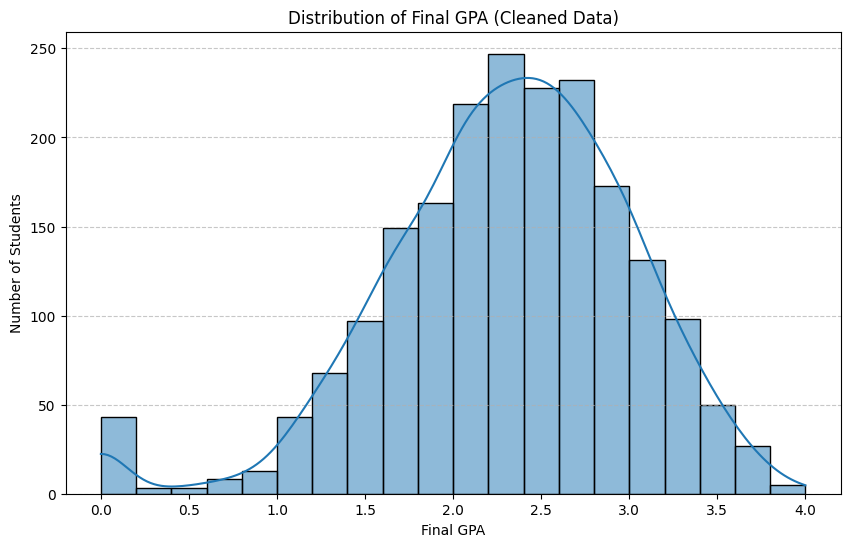

In [157]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(analysis['final_gpa'].dropna(), bins=20, kde=True)
plt.title('Distribution of Final GPA (Cleaned Data)')
plt.xlabel('Final GPA')
plt.ylabel('Number of Students')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

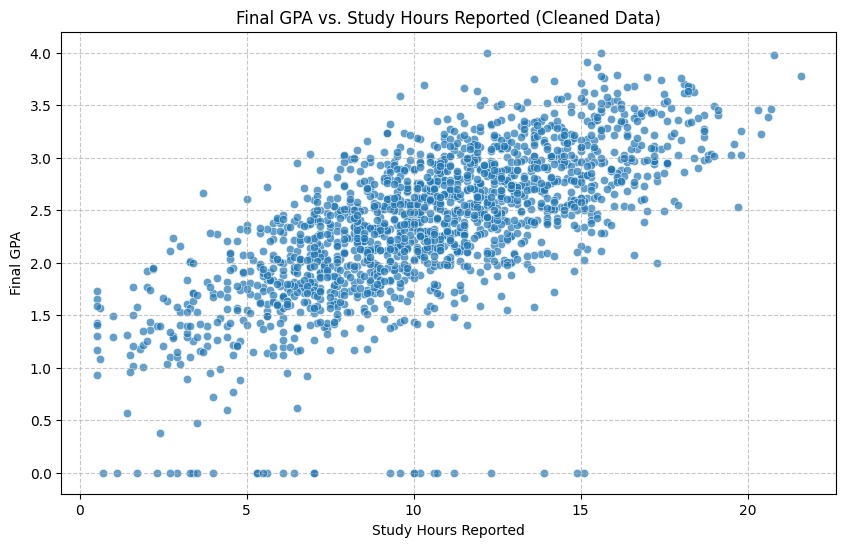

In [158]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.scatterplot(x='study_hours_reported', y='final_gpa', data=analysis, alpha=0.7)
plt.title('Final GPA vs. Study Hours Reported (Cleaned Data)')
plt.xlabel('Study Hours Reported')
plt.ylabel('Final GPA')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()